## TASK 1 - Blob detection
Group Number: #INSERT HERE

### 1. Data import and preparation

Read an input image from your local directory as grayscale and normalize the values between 0 and 1.

In [1]:
%load_ext autoreload
%autoreload 1
%aimport filters, utils
from skimage.feature import peak_local_max
import matplotlib.pyplot as plt
import numpy as np
import filters
import utils
import cv2

# Adjust size of image plot here
plt.rcParams['figure.figsize'] = [8, 5]
plt.rcParams['figure.dpi'] = 150

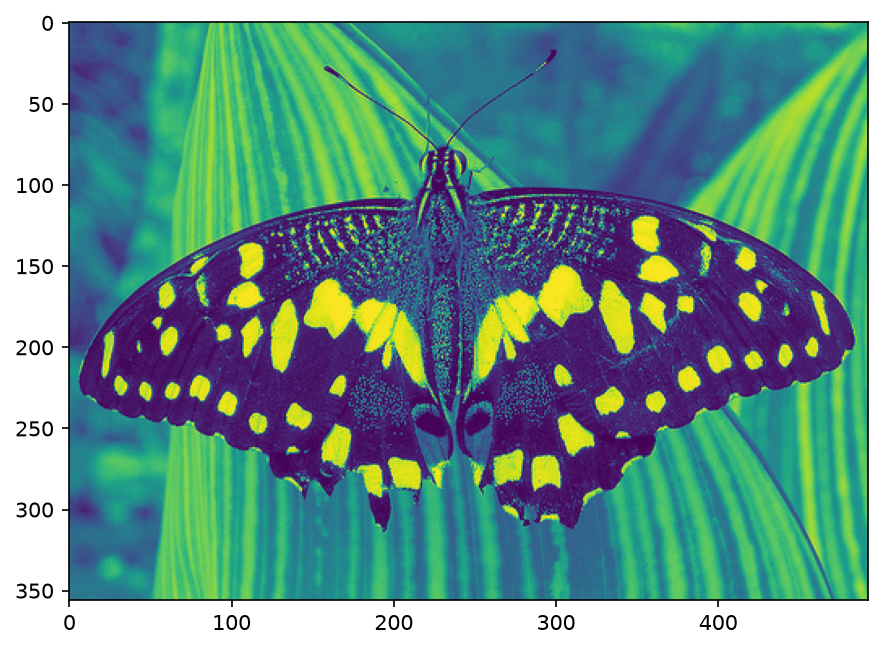

In [2]:
#student_code start

img = cv2.imread('data/butterfly.jpg', cv2.IMREAD_GRAYSCALE)
normalized = img.astype(np.float32)/255.

plt.imshow(normalized)

#student_code end

### 2. Scale Space Creation

Generate the image pyramid using ***get_log_pyramid(..)*** in _filters.py_. Check your results with ***utils.show_plot(..)***

***Submission:*** Save the *third level* of the image scale space of the butterfly as **task1_filtered.png** using ***utils.show_plot(..)***.


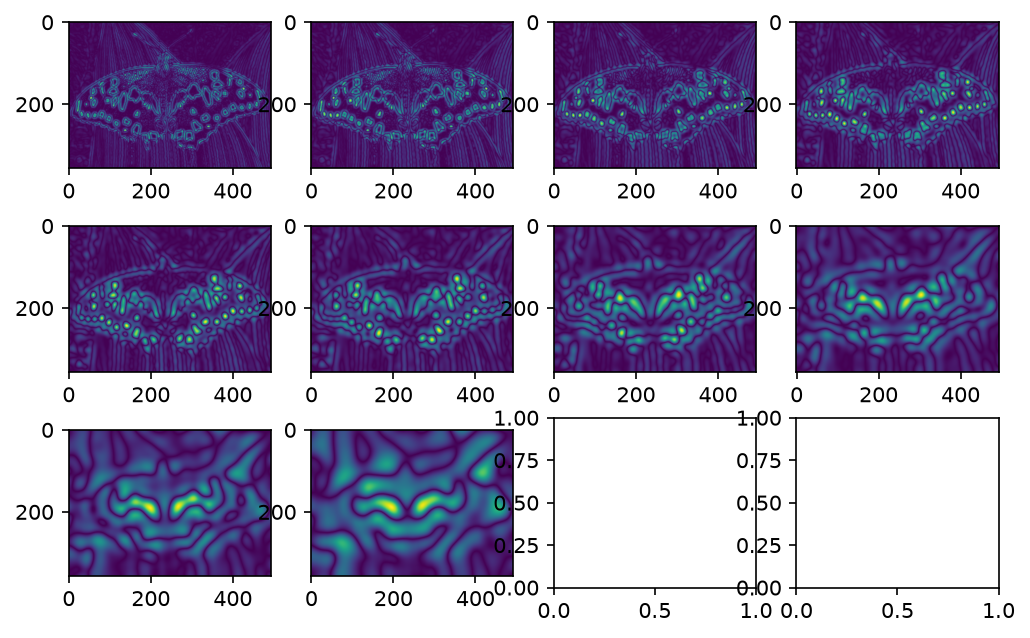

In [45]:
sigma = 2.
k = 1.3
levels = 10

#student_code start

import filters


images, sigmas = filters.get_log_pyramid(normalized, sigma, k, levels)

fig, ax = plt.subplots(3,4)
ax = ax.flatten()
for i in range(images.shape[0]):

    ax[i].imshow(images[i])

factor = k
s = sigma

#student_code end

### 2. Blob detection

Perform the first step of the non-maximum suppression by setting the values in the scale space below a certain threshold to zero. Then, look for maxima in a defined local neighbourhood, in this case: the 26-connection. ***skimage.feature.peak_local_max(..)*** is useful to obtain local maxima. Complete method ***utils.show_blobs(..)*** and plot the blobs.


***Submission:*** Save the image including the blobs as **task1_blobs_full.png** (threshold around 0.3).

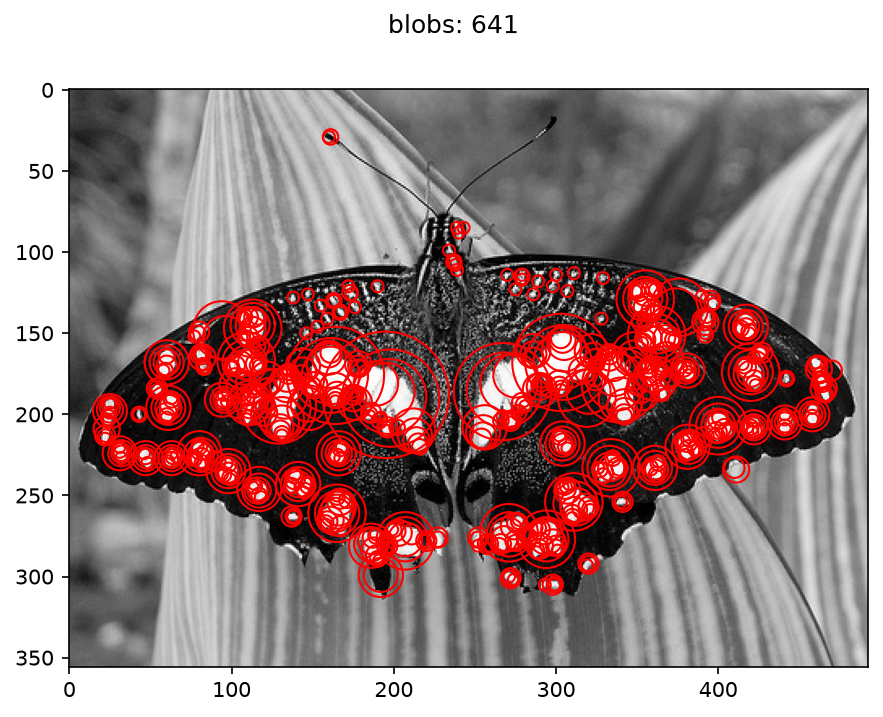

In [51]:
thres = 0.3

#student_code start

import utils

img_t = np.where(images < thres, 0, images)

local_maxes = []

for i in range(img_t.shape[0]):
    local_max = peak_local_max(img_t[i], exclude_border=False)
    local_maxes.append(np.column_stack((local_max, np.ones(local_max.shape[0]) * i)))


peaks = np.vstack(local_maxes)


utils.show_blobs(normalized, peaks, sigmas)

#student_code end


### 3. Evaluation 

Apply the process to a half-sized version of the input image. Plot your results as well with ***utils.show_blobs(..)***.

_***HINT:***_
_cv2.resize(..)_


***Submission:*** Save the result as **task1_blobs_half.png**.

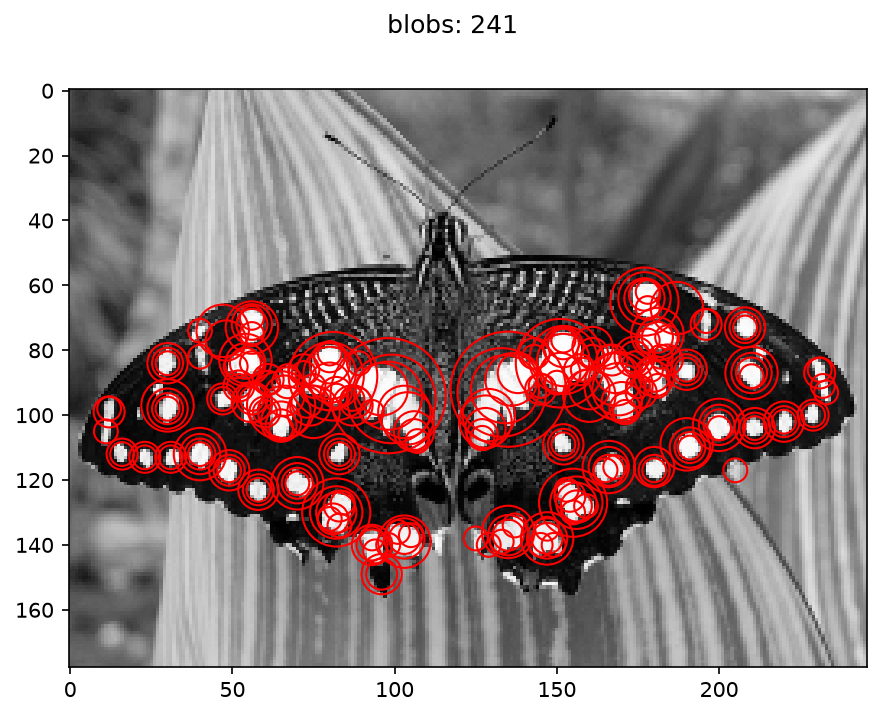

In [50]:
#student_code start

resized= cv2.resize(normalized, None, fx=0.5, fy=0.5)

r_images, r_sigmas = filters.get_log_pyramid(resized, sigma, k, levels)

r_img_t = np.where(r_images < thres, 0, r_images)

r_local_maxes = []

for i in range(r_img_t.shape[0]):
    r_local_max = peak_local_max(r_img_t[i], exclude_border=False)
    r_local_maxes.append(np.column_stack((r_local_max, np.ones(r_local_max.shape[0]) * i)))


r_peaks = np.vstack(r_local_maxes)


utils.show_blobs(resized, r_peaks, r_sigmas)

#student_code end

*** 
#### Taking a close look at the detected blobs on different image scales, is the method able to find blobs in a scale-invariant way? What could be reasons for observed errors or inaccurately detected blobs? 

#ANSWER HERE

#### 3.1 LoG Response

Pick a detected keypoint and plot the response of the LoG for all scales in both image versions. The outcome should be a 2D plot where the x-axis represents the scale of the filter and the y-axis the filter response at the selected keypoint position. 

_***HINT:***_
_plt.plot(..)_

In [6]:
#student_code start

#student_code end

*** 
#### Describe and explain the difference between the two LoG response curves.

#ANSWER_HERE

#### 3.2 Own Image

Import an image of your choice and apply the process once again. 


***Submission:*** Save the image including blobs with ***utils.show_blobs(..)*** as: **task1_blobs_own.png**

In [7]:
#student_code start

#student_code end